# Summary analysis of saved results

Read saved outputs from notebooks 03–08 and their CSVs. Do not refit models,
recompute MI, or evaluate test rows. Cluster descriptions reuse saved assignments
and the same training-only sample. Install `lxml` before running this notebook.

## 1. Environment and inputs

In [1]:
from pathlib import Path
from io import StringIO
from itertools import combinations
import ast
import hashlib
import json
import platform
import re
import sys
import time

experiment_started = time.perf_counter()
import lxml
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from threadpoolctl import threadpool_info, threadpool_limits
get_ipython().run_line_magic("matplotlib", "inline")
thread_limit = threadpool_limits(limits=1)
cwd = Path.cwd()
repo_root = cwd if (cwd / "src/unsupervised_common.py").exists() else cwd.parent
assert (repo_root / "src/unsupervised_common.py").exists(), "Open from the repository root or notebooks/."
sys.path.insert(0, str(repo_root / "src"))
from preprocessing import NUMERIC_COLUMNS
from unsupervised_common import load_training_data, clustering_sample
results_dir = repo_root / "results"
K_VALUES = [5, 10, 15, 17, 20, 25, 33]
MODELS = ["Random Forest", "GaussianNB", "Logistic Regression", "k-NN"]
TIME_COLUMNS = ["MI_seconds_mean", "preprocessing_seconds_mean", "fit_seconds_mean", "predict_seconds_mean"]
protected_paths = [p for folder in ["notebooks", "scripts", "src", "results"]
                   for p in (repo_root / folder).iterdir() if p.is_file()
                   and not p.name.startswith(("09_summary_analysis", "build_summary_notebook", "summary_"))]
input_hashes = {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in protected_paths}
print(f"Python {platform.python_version()}; sklearn {sklearn.__version__}; pandas {pd.__version__}; numpy {np.__version__}")

Python 3.13.3; sklearn 1.9.1; pandas 3.1.1; numpy 2.5.4


## 2. Initial-CV timing, including feature selection

RF/GaussianNB times come from notebook 03's saved HTML summary, rounded to four
decimal places. LR/k-NN times retain the CSV's saved precision. Totals sum the
four recorded mean times; ratios use each model's k=33 total as the denominator.

,source,models,decimal_places,rounding_evidence,source_cell_index
0,03 saved HTML,Random Forest; GaussianNB,4,summary.round(4); HTML fractional values have ...,6.0
1,lr_knn_cv_summary.csv,Logistic Regression; k-NN,stored CSV precision,No additional rounding before aggregation,NaN


,model,k,MI_seconds_mean,preprocessing_seconds_mean,fit_seconds_mean,predict_seconds_mean,total_with_MI_seconds_mean,total_without_MI_seconds_mean,relative_to_k33,relative_without_MI_to_k33
0,Random Forest,5,0.571700,0.029500,4.954900,0.121600,5.677700,5.106000,0.473564,0.425880
1,Random Forest,10,0.549900,0.044900,8.454300,0.136300,9.185400,8.635500,0.766133,0.720267
2,Random Forest,15,0.590000,0.097400,10.145400,0.144800,10.977600,10.387600,0.915616,0.866406
3,Random Forest,17,0.529100,0.067800,9.337900,0.139500,10.074300,9.545200,0.840274,0.796143
4,Random Forest,20,0.558200,0.087100,9.787700,0.139300,10.572300,10.014100,0.881811,0.835253
5,Random Forest,25,0.545600,0.100900,10.628500,0.144500,11.419500,10.873900,0.952474,0.906967
6,Random Forest,33,0.000000,0.149900,11.693600,0.145800,11.989300,11.989300,1.000000,1.000000
7,GaussianNB,5,0.546400,0.029900,0.014200,0.003600,0.594100,0.047700,3.057643,0.245497
8,GaussianNB,10,0.558400,0.047900,0.015300,0.004200,0.625800,0.067400,3.220793,0.346886
9,GaussianNB,15,0.531600,0.064700,0.017000,0.004400,0.617700,0.086100,3.179104,0.443129


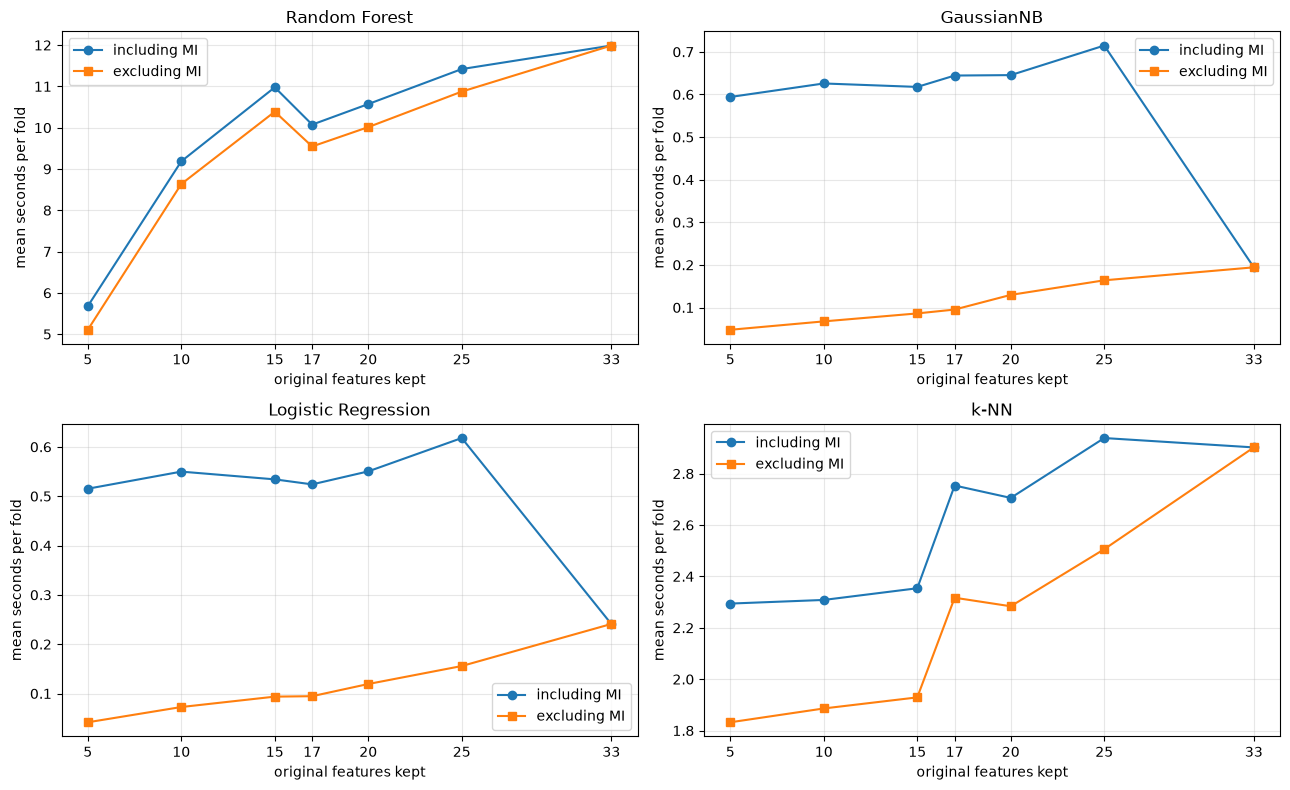

In [2]:
path03 = repo_root / "notebooks/03_classification_comparison.ipynb"
saved03 = json.loads(path03.read_text())
candidates = []
for cell_index, cell in enumerate(saved03["cells"]):
    for output in cell.get("outputs", []):
        if "text/html" not in output.get("data", {}):
            continue
        html = "".join(output["data"]["text/html"])
        for frame in pd.read_html(StringIO(html), flavor="lxml", index_col=0):
            if {"model", "k", *TIME_COLUMNS}.issubset(frame.columns):
                candidates.append((cell_index, frame, html))
assert len(candidates) == 1, "Cannot uniquely read the saved initial-CV HTML summary; stop here."
source_cell, saved_times, source_html = candidates[0]
source_code = "".join(saved03["cells"][source_cell]["source"])
rounding = [node.args[0].value for node in ast.walk(ast.parse(source_code))
            if isinstance(node, ast.Call) and isinstance(node.func, ast.Attribute)
            and node.func.attr == "round" and isinstance(node.func.value, ast.Name)
            and node.func.value.id == "summary" and node.args
            and isinstance(node.args[0], ast.Constant)]
saved_numeric_strings = re.findall(r"<td>\s*(-?\d+\.\d+)\s*</td>", source_html)
observed_decimal_places = sorted({len(value.split(".")[1]) for value in saved_numeric_strings})
assert rounding == [4] and observed_decimal_places == [4]
assert len(saved_times) == 14 and set(saved_times.model) == {"Random Forest", "GaussianNB"}
assert set(saved_times.k) == set(K_VALUES)
csv_times = pd.read_csv(results_dir / "lr_knn_cv_summary.csv")
initial_times = pd.concat([
    saved_times[["model", "k"] + TIME_COLUMNS].assign(source="03 saved HTML", source_decimal_places=4),
    csv_times[["model", "k"] + TIME_COLUMNS].assign(source="lr_knn_cv_summary.csv", source_decimal_places=np.nan),
], ignore_index=True)
initial_times["total_with_MI_seconds_mean"] = initial_times[TIME_COLUMNS].sum(axis=1)
initial_times["total_without_MI_seconds_mean"] = initial_times[TIME_COLUMNS[1:]].sum(axis=1)
k33_total = initial_times.loc[initial_times.k == 33].set_index("model")["total_with_MI_seconds_mean"]
initial_times["relative_to_k33"] = initial_times.total_with_MI_seconds_mean / initial_times.model.map(k33_total)
initial_times["relative_without_MI_to_k33"] = initial_times.total_without_MI_seconds_mean / initial_times.model.map(k33_total)
initial_times["_order"] = initial_times.model.map({name: i for i, name in enumerate(MODELS)})
initial_times = initial_times.sort_values(["_order", "k"]).drop(columns="_order").reset_index(drop=True)
initial_times.to_csv(results_dir / "summary_initial_cv_times.csv", index=False)
precision = pd.DataFrame([
    {"source": "03 saved HTML", "models": "Random Forest; GaussianNB", "decimal_places": "4",
     "rounding_evidence": "summary.round(4); HTML fractional values have four digits", "source_cell_index": source_cell},
    {"source": "lr_knn_cv_summary.csv", "models": "Logistic Regression; k-NN", "decimal_places": "stored CSV precision",
     "rounding_evidence": "No additional rounding before aggregation", "source_cell_index": None},
])
precision.to_csv(results_dir / "summary_source_precision.csv", index=False)
display(precision)
display(initial_times.drop(columns=["source", "source_decimal_places"]).round(6))
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, model in zip(axes.flat, MODELS):
    group = initial_times.loc[initial_times.model == model]
    ax.plot(group.k, group.total_with_MI_seconds_mean, marker="o", label="including MI")
    ax.plot(group.k, group.total_without_MI_seconds_mean, marker="s", label="excluding MI")
    ax.set(title=model, xlabel="original features kept", ylabel="mean seconds per fold")
    ax.set_xticks(K_VALUES)
    ax.legend()
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## 3. Repeated timing for the no-removal calculation

Some recorded fit/predict means differ by about 30–40% for the same calculation.
Percent differences below use (08 minus 06) divided by 06. Both tables use five folds.

In [3]:
lof_summary = pd.read_csv(results_dir / "lof_cv_summary.csv")
iforest_summary = pd.read_csv(results_dir / "iforest_cv_summary.csv")
timing_fields = ["model", "fit_seconds_mean", "predict_seconds_mean"]
timing_variation = lof_summary.loc[lof_summary.condition == "No removal", timing_fields].merge(
    iforest_summary.loc[iforest_summary.condition == "No removal", timing_fields],
    on="model", suffixes=("_06", "_08"), validate="one_to_one"
)
for metric in ["fit", "predict"]:
    timing_variation[f"{metric}_difference_pct_vs_06"] = (
        (timing_variation[f"{metric}_seconds_mean_08"] - timing_variation[f"{metric}_seconds_mean_06"])
        / timing_variation[f"{metric}_seconds_mean_06"] * 100
    )
timing_variation = timing_variation.set_index("model").loc[MODELS].reset_index()
timing_variation.to_csv(results_dir / "summary_no_removal_timing.csv", index=False)
display(timing_variation.round(6))

,model,fit_seconds_mean_06,predict_seconds_mean_06,fit_seconds_mean_08,predict_seconds_mean_08,fit_difference_pct_vs_06,predict_difference_pct_vs_06
0,Random Forest,13.946476,0.198513,10.001664,0.164516,-28.285371,-17.125506
1,GaussianNB,0.019638,0.002718,0.015750,0.002708,-19.796822,-0.356568
2,Logistic Regression,0.056946,0.000400,0.036865,0.000240,-35.262929,-40.066166
3,k-NN,0.000907,2.845016,0.000822,2.159097,-9.453929,-24.109477


## 4. MI selection stability across folds

Read LR's saved feature lists; the MI data, folds, seed, and function are shared
by all four classifiers. For k=33, every feature is retained without MI ranking.

In [4]:
saved_folds = pd.read_csv(results_dir / "lr_knn_cv_folds.csv")
selections = saved_folds.loc[saved_folds.model == "Logistic Regression", ["fold", "k", "selected_features"]].copy()
selected_sets = {}
for row in selections.itertuples():
    features = json.loads(row.selected_features)
    assert len(features) == row.k and len(set(features)) == row.k
    selected_sets[(row.fold, row.k)] = set(features)
assert len(selected_sets) == 35
full_mi = pd.read_csv(results_dir / "knn_final_mi.csv")
all_features = full_mi.feature.tolist()
assert len(all_features) == 33 and len(set(all_features)) == 33
stability_rows = []
frequency = pd.DataFrame(index=pd.Index(all_features, name="feature"))
for k in K_VALUES:
    sets = [selected_sets[(fold, k)] for fold in range(1, 6)]
    intersection, union = set.intersection(*sets), set.union(*sets)
    stability_rows.append({"k": k, "all_five_count": len(intersection), "any_fold_count": len(union),
                           "all_five_features": json.dumps(sorted(intersection)),
                           "any_fold_features": json.dumps(sorted(union))})
    frequency[f"k_{k}"] = [sum(feature in values for values in sets) for feature in all_features]
stability = pd.DataFrame(stability_rows)
selections.sort_values(["k", "fold"]).to_csv(results_dir / "summary_feature_selections.csv", index=False)
stability.to_csv(results_dir / "summary_mi_stability.csv", index=False)
frequency.to_csv(results_dir / "summary_mi_selection_frequency.csv")
display(stability[["k", "all_five_count", "any_fold_count"]])
with pd.option_context("display.max_rows", None):
    display(frequency)
stable17 = set.intersection(*(selected_sets[(fold, 17)] for fold in range(1, 6)))
full_top17 = set(full_mi.feature.head(17))
comparison17 = pd.DataFrame({
    "feature": all_features, "full_training_MI_rank": range(1, 34),
    "folds_selected_at_k17": frequency["k_17"].to_numpy(),
    "all_five_at_k17": [feature in stable17 for feature in all_features],
    "full_training_top17": [feature in full_top17 for feature in all_features],
})
comparison17.to_csv(results_dir / "summary_mi_k17_vs_full_training.csv", index=False)
display(comparison17.loc[comparison17.all_five_at_k17])
print("Shared stable/full-training top-17 features:", len(stable17 & full_top17))
print("Stable-only features:", sorted(stable17 - full_top17))
print("Full-training-top-17-only features:", sorted(full_top17 - stable17))
jaccard_rows = []
for k in [5, 17]:
    for a, b in combinations(range(1, 6), 2):
        left, right = selected_sets[(a, k)], selected_sets[(b, k)]
        overlap, union = len(left & right), len(left | right)
        jaccard_rows.append({"k": k, "fold_a": a, "fold_b": b, "intersection_count": overlap,
                             "union_count": union, "Jaccard": overlap / union})
jaccard_pairs = pd.DataFrame(jaccard_rows)
jaccard_summary = jaccard_pairs.groupby("k").agg(
    pair_count=("Jaccard", "size"), Jaccard_mean=("Jaccard", "mean"),
    Jaccard_min=("Jaccard", "min"), Jaccard_max=("Jaccard", "max")
).reset_index()
jaccard_pairs.to_csv(results_dir / "summary_mi_jaccard_pairs.csv", index=False)
jaccard_summary.to_csv(results_dir / "summary_mi_jaccard_summary.csv", index=False)
display(jaccard_pairs.round(6))
display(jaccard_summary.round(6))

,k,all_five_count,any_fold_count
0,5,4,7
1,10,9,11
2,15,15,15
3,17,17,17
4,20,18,22
5,25,24,27
6,33,33,33


,k_5,k_10,k_15,k_17,k_20,k_25,k_33
feature,,,,,,,
detailed_occupation_recode,5,5,5,5,5,5,5
major_occupation_code,5,5,5,5,5,5,5
education,5,5,5,5,5,5,5
weeks_worked_in_year,2,5,5,5,5,5,5
capital_gains,2,5,5,5,5,5,5
detailed_industry_recode,5,5,5,5,5,5,5
major_industry_code,1,5,5,5,5,5,5
dividends_from_stocks,0,5,5,5,5,5,5
num_persons_worked_for_employer,0,1,5,5,5,5,5


,feature,full_training_MI_rank,folds_selected_at_k17,all_five_at_k17,full_training_top17
0,detailed_occupation_recode,1,5,True,True
1,major_occupation_code,2,5,True,True
2,education,3,5,True,True
3,weeks_worked_in_year,4,5,True,True
4,capital_gains,5,5,True,True
5,detailed_industry_recode,6,5,True,True
6,major_industry_code,7,5,True,True
7,dividends_from_stocks,8,5,True,True
8,num_persons_worked_for_employer,9,5,True,True
9,age,10,5,True,True


Shared stable/full-training top-17 features: 17
Stable-only features: []
Full-training-top-17-only features: []


,k,fold_a,fold_b,intersection_count,union_count,Jaccard
0,5,1,2,4,6,0.666667
1,5,1,3,4,6,0.666667
2,5,1,4,5,5,1.000000
3,5,1,5,4,6,0.666667
4,5,2,3,5,5,1.000000
5,5,2,4,4,6,0.666667
6,5,2,5,4,6,0.666667
7,5,3,4,4,6,0.666667
8,5,3,5,4,6,0.666667
9,5,4,5,4,6,0.666667


,k,pair_count,Jaccard_mean,Jaccard_min,Jaccard_max
0,5,10,0.733333,0.666667,1.0
1,17,10,1.000000,1.000000,1.0


## 5. Saved k=4 cluster descriptions

Recreate only the shared sample order; do not fit preprocessing or clustering.
Numeric summaries use the seven original numeric features. Categorical summaries
use the full-training MI top-17 categorical features. Missing values count as a
category; modal ties are resolved lexically. Income is used for descriptions only.

In [5]:
data = load_training_data(repo_root)
X_cluster, y_cluster = clustering_sample(data.X_dev, data.y_dev)
kmeans_assignments = pd.read_csv(results_dir / "kmeans_assignments.csv")
ward_assignments = pd.read_csv(results_dir / "ward_assignments.csv")
for frame in [kmeans_assignments, ward_assignments]:
    assert len(frame) == 10_000
    assert np.array_equal(frame.row_index.to_numpy(), X_cluster.index.to_numpy())
assignment_sources = {
    "K-Means": (kmeans_assignments, "cluster_k_"),
    "Ward": (ward_assignments, "ward_cluster_k_"),
}
categorical_features = [feature for feature in full_mi.feature.head(17) if feature not in NUMERIC_COLUMNS]
numeric_rows, categorical_rows = [], []
for method, (frame, prefix) in assignment_sources.items():
    labels = frame[f"{prefix}4"].to_numpy()
    for cluster in sorted(np.unique(labels)):
        mask = labels == cluster
        group = X_cluster.loc[mask]
        numeric_rows.append({
            "method": method, "k": 4, "cluster": int(cluster), "count": int(mask.sum()),
            "high_income_rate": float(y_cluster.iloc[mask].mean()),
            **{f"{column}_mean": float(group[column].mean()) for column in NUMERIC_COLUMNS},
        })
        for feature in categorical_features:
            counts = group[feature].fillna("Missing").astype(str).value_counts(dropna=False)
            mode_count = int(counts.max())
            mode = sorted(counts.index[counts == mode_count].tolist())[0]
            categorical_rows.append({"method": method, "k": 4, "cluster": int(cluster),
                                     "feature": feature, "mode": mode, "mode_count": mode_count,
                                     "mode_fraction": mode_count / len(group)})
cluster_numeric = pd.DataFrame(numeric_rows)
cluster_categorical = pd.DataFrame(categorical_rows)
cluster_numeric.to_csv(results_dir / "summary_cluster_numeric_k4.csv", index=False)
cluster_categorical.to_csv(results_dir / "summary_cluster_categorical_k4.csv", index=False)
with pd.option_context("display.max_columns", None, "display.max_rows", None):
    display(cluster_numeric.round(6))
    display(cluster_categorical.round(6))
cross = pd.crosstab(kmeans_assignments.cluster_k_4, ward_assignments.ward_cluster_k_4,
                    rownames=["kmeans_cluster"], colnames=["ward_cluster"])
cross.rename(columns=lambda value: f"ward_cluster_{value}").to_csv(
    results_dir / "summary_cluster_crosstab_k4.csv", index_label="kmeans_cluster"
)
display(cross)

,method,k,cluster,count,high_income_rate,age_mean,wage_per_hour_mean,capital_gains_mean,capital_losses_mean,dividends_from_stocks_mean,num_persons_worked_for_employer_mean,weeks_worked_in_year_mean
0,K-Means,4,0,6095,0.123544,38.791468,2.391961,431.796719,69.903856,202.615422,3.690402,45.466776
1,K-Means,4,1,685,0.045255,37.735766,1040.144526,297.951825,34.959124,140.553285,4.135766,46.335766
2,K-Means,4,2,3199,0.018443,57.619569,0.754923,155.584870,16.421694,472.694905,0.282901,1.503907
3,K-Means,4,3,21,0.857143,45.619048,0.000000,99999.000000,0.000000,3670.380952,3.238095,48.000000
4,Ward,4,0,6144,0.111654,38.877930,115.239583,434.428874,0.101725,94.112630,3.786621,46.735840
5,Ward,4,1,3573,0.021271,54.852785,1.147495,185.973412,0.861181,498.323818,0.568430,4.265043
6,Ward,4,2,262,0.309160,44.858779,66.263359,0.000000,1903.977099,1849.740458,3.568702,43.080153
7,Ward,4,3,21,0.857143,45.619048,0.000000,99999.000000,0.000000,3670.380952,3.238095,48.000000


,method,k,cluster,feature,mode,mode_count,mode_fraction
0,K-Means,4,0,detailed_occupation_recode,2,572,0.093847
1,K-Means,4,0,major_occupation_code,Professional specialty,938,0.153897
2,K-Means,4,0,education,High school graduate,1905,0.312551
3,K-Means,4,0,detailed_industry_recode,33,942,0.154553
4,K-Means,4,0,major_industry_code,Retail trade,942,0.154553
5,K-Means,4,0,class_of_worker,Private,4174,0.684824
6,K-Means,4,0,sex,Male,3244,0.532240
7,K-Means,4,0,tax_filer_stat,Joint both under 65,3462,0.568007
8,K-Means,4,0,detailed_household_and_family_stat,Householder,2484,0.407547
9,K-Means,4,0,detailed_household_summary_in_household,Householder,3278,0.537818


ward_cluster,0,1,2,3
kmeans_cluster,,,,
0,5455,414,226,0
1,669,4,12,0
2,20,3155,24,0
3,0,0,0,21


## 6. Income-label purity of saved clusters

Purity is the sum of each cluster's majority-class count divided by 10,000.
The one-cluster reference is the sample's low-income proportion, 0.9139.
No assignments are fitted or changed for this calculation.

In [6]:
purity_rows = []
purity_baseline = float(y_cluster.eq(0).mean())
for method, (frame, prefix) in assignment_sources.items():
    for k in range(2, 11):
        labels = frame[f"{prefix}{k}"].to_numpy()
        assert len(np.unique(labels)) == k
        class_counts = pd.crosstab(labels, y_cluster.to_numpy()).reindex(columns=[0, 1], fill_value=0)
        majority_count = int(class_counts.max(axis=1).sum())
        purity_rows.append({"method": method, "k": k, "majority_correct_count": majority_count,
                            "sample_count": len(y_cluster), "purity": majority_count / len(y_cluster),
                            "single_cluster_baseline": purity_baseline,
                            "difference_from_baseline": majority_count / len(y_cluster) - purity_baseline})
purity = pd.DataFrame(purity_rows)
purity.to_csv(results_dir / "summary_cluster_purity.csv", index=False)
display(purity.round(6))

,method,k,majority_correct_count,sample_count,purity,single_cluster_baseline,difference_from_baseline
0,K-Means,2,9139,10000,0.9139,0.9139,0.0000
1,K-Means,3,9139,10000,0.9139,0.9139,0.0000
2,K-Means,4,9154,10000,0.9154,0.9139,0.0015
3,K-Means,5,9139,10000,0.9139,0.9139,0.0000
4,K-Means,6,9160,10000,0.9160,0.9139,0.0021
5,K-Means,7,9154,10000,0.9154,0.9139,0.0015
6,K-Means,8,9164,10000,0.9164,0.9139,0.0025
7,K-Means,9,9158,10000,0.9158,0.9139,0.0019
8,K-Means,10,9164,10000,0.9164,0.9139,0.0025
9,Ward,2,9139,10000,0.9139,0.9139,0.0000


## 7. Final checks and execution time

In [7]:
assert len(initial_times) == 28
assert set(initial_times.model) == set(MODELS)
assert initial_times.groupby("model").k.apply(lambda values: set(values) == set(K_VALUES)).all()
assert initial_times.loc[initial_times.k == 33, "MI_seconds_mean"].eq(0).all()
assert np.allclose(initial_times.loc[initial_times.k == 33, "relative_to_k33"], 1)
assert np.allclose(initial_times.total_with_MI_seconds_mean, initial_times[TIME_COLUMNS].sum(axis=1))
assert len(timing_variation) == 4 and len(precision) == 2
assert len(selections) == 35 and len(selected_sets) == 35
assert set(selections.fold) == set(range(1, 6))
assert len(stability) == 7 and frequency.shape == (33, 7)
assert frequency.min().min() >= 0 and frequency.max().max() <= 5
assert frequency.k_33.eq(5).all()
assert (np.diff(frequency.to_numpy(), axis=1) >= 0).all()
assert stability.loc[stability.k == 33, "all_five_count"].iloc[0] == 33
assert len(jaccard_pairs) == 20 and jaccard_summary.pair_count.eq(10).all()
assert jaccard_pairs.Jaccard.between(0, 1).all()
assert len(data.X_dev) == 30_000 and len(data.folds) == 5 and X_cluster.shape == (10_000, 33)
assert len(cluster_numeric) == 8
assert len(cluster_categorical) == 8 * len(categorical_features)
assert len(NUMERIC_COLUMNS) == 7 and cluster_numeric.groupby("method")["count"].sum().eq(10_000).all()
assert cross.shape == (4, 4) and cross.to_numpy().sum() == 10_000
assert len(purity) == 18 and set(purity.k) == set(range(2, 11))
assert np.isclose(purity_baseline, 0.9139, rtol=0, atol=1e-12)
assert purity.purity.between(purity_baseline, 1).all()
for method, prefix in [("K-Means", "kmeans"), ("Ward", "ward")]:
    saved = pd.read_csv(results_dir / f"{prefix}_cluster_profiles.csv")
    current = cluster_numeric.loc[cluster_numeric.method == method].sort_values("cluster")
    reference = saved.loc[saved.k == 4].sort_values("cluster")
    assert np.array_equal(current["count"], reference["count"])
    assert np.allclose(current.high_income_rate, reference.high_income_rate, rtol=0, atol=1e-12)
assert all(hashlib.sha256(Path(path).read_bytes()).hexdigest() == digest for path, digest in input_hashes.items())
assert all(item["num_threads"] == 1 for item in threadpool_info())
total_seconds = time.perf_counter() - experiment_started
pd.DataFrame([{"total_seconds": total_seconds, "python": platform.python_version(),
               "sklearn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__,
               "native_threads": 1, "saved_03_decimal_places": 4}]).to_csv(
    results_dir / "summary_execution.csv", index=False
)
print("Final checks passed.")
print(f"Total execution time: {total_seconds:.2f} seconds")

Final checks passed.
Total execution time: 4.06 seconds
